# Interview Twin - Training the Question Difficulty Classifier

**Goal:** teach a computer to read an interview question and predict whether it is **Easy, Medium or Hard**.

**Type of problem:** *supervised classification*. "Supervised" means we have examples where the right answer (the label) is already known, so the model can learn from them. Here:
- **Input (X):** the text of the question
- **Output (y):** the difficulty label

**Pipeline in this notebook** (run the cells top to bottom):
1. Load the data -> 2. Clean it -> 3. Look at class balance -> 4. Preprocess text -> 5. Encode labels -> 6. Split into train/test -> 7. TF-IDF -> 8. Train Logistic Regression -> 9. Evaluate -> 10. Understand what it learned -> 11. Predict new questions -> 12. Save the model

The Flask website **never retrains**. It only loads the two files saved at the end of this notebook.

## Step 1 - Imports
Each library has one job: `pandas` for tables, `re` for text cleaning, `scikit-learn` for the machine learning, `joblib` for saving models, `matplotlib` for charts.

In [1]:
import re, sys, json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42        # a fixed 'random seed' makes every random step repeatable, so you always get the same numbers
ROOT = Path.cwd().parent          # this notebook lives in <project>/notebooks
print('Project folder:', ROOT)

Project folder: /home/claude/interview-twin


## Step 2 - Load the data
The file `unified_questions.csv` was produced by `backend/data_prep.py` from your two original CSV files. Each row is one question.

In [2]:
df = pd.read_csv(ROOT / 'data' / 'processed' / 'unified_questions.csv').fillna('')
print(df.shape)
df[['question', 'difficulty', 'status', 'category', 'topic']].head()

(5899, 12)


,question,difficulty,status,category,topic
0,What is the difference between compilation and...,Medium,converted,Software Interview Bank,General Programming
1,Explain the concept of polymorphism.,Medium,converted,Software Interview Bank,General Programming
2,Define encapsulation and give an example.,Hard,converted,Software Interview Bank,General Programming
3,"What is an abstract class, and how is it diffe...",Medium,converted,Software Interview Bank,General Programming
4,Describe the principles of Object-Oriented Pro...,Medium,converted,Software Interview Bank,General Programming


## Step 3 - Clean the data
Bad data gives a bad model, so we remove:
- **Duplicates** (`status == 'duplicate'`) - if the same question were in both train and test sets, the test score would be unfairly high. This is one kind of **data leakage**.
- **Invalid rows** and rows with a **missing or unknown difficulty label** - the model cannot learn from them.
- Rows with **empty question text**.

In [3]:
print('Row status counts:'); print(df['status'].value_counts(), '\n')
LABELS = ['Easy', 'Medium', 'Hard']

data = df[~df['status'].isin(['duplicate', 'invalid'])]
data = data[data['difficulty'].isin(LABELS) & (data['question'].str.strip() != '')].copy()
print('Rows kept for training/testing:', len(data))

Row status counts:
status
converted       3700
needs_review    1928
duplicate        271
Name: count, dtype: int64 

Rows kept for training/testing: 5628


## Step 4 - Preprocess the text
Computers need consistent text. We lowercase it, remove most punctuation and extra spaces, but **keep symbols that matter in tech** such as `c++`, `c#`, `node.js`, `ci/cd`. We also remove the phrase `Complete the statement and explain:` that our converter added, because it carries no information about difficulty.

In [4]:
PREFIX = re.compile(r'^complete the statement and explain:\s*', re.I)

def preprocess(text):
    t = PREFIX.sub('', str(text)).lower()
    t = re.sub(r'https?://\S+', ' ', t)
    t = re.sub(r'[^a-z0-9+#./\- ]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

print(preprocess('Complete the statement and explain: What is CI/CD in C++ projects?!'))
data['text'] = data['question'].map(preprocess)
data = data.drop_duplicates('text').reset_index(drop=True)      # duplicates that only appear after cleaning
print('After removing duplicates created by cleaning:', len(data))

what is ci/cd in c++ projects
After removing duplicates created by cleaning: 5624


## Step 5 - Look at the class balance
Are Easy, Medium and Hard equally common? If not, the data is **imbalanced**. A lazy model can then score well by always guessing the most common class, so *accuracy alone can mislead*. Remember this when you read the results.

difficulty
Easy       973
Medium    2506
Hard      2145
Name: count, dtype: int64


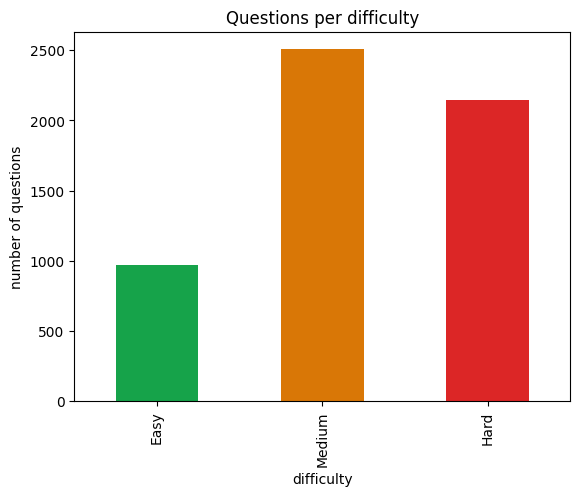

In [5]:
counts = data['difficulty'].value_counts().reindex(LABELS)
print(counts)
counts.plot(kind='bar', color=['#16a34a', '#d97706', '#dc2626'], title='Questions per difficulty')
plt.ylabel('number of questions'); plt.show()

## Step 6 - Encode the labels
Models work with numbers, not words. `LabelEncoder` turns each label into a number. (scikit-learn can also accept text labels directly and does this for us internally, so we keep the text labels for the final model, which keeps the Flask code simple. We show the encoding here so you can see it.)

In [6]:
enc = LabelEncoder().fit(LABELS)
print(dict(zip(enc.classes_, enc.transform(enc.classes_))))   # alphabetical: Easy=0, Hard=1, Medium=2

{np.str_('Easy'): np.int64(0), np.str_('Hard'): np.int64(1), np.str_('Medium'): np.int64(2)}


## Step 7 - Split into training and testing sets
- The **training set (80%)** is what the model learns from.
- The **test set (20%)** is hidden until the end. It tells us how the model does on questions it has **never seen** - the honest measure.
- `stratify=y` keeps the Easy/Medium/Hard proportions the same in both sets.
- `random_state=SEED` makes the split repeatable.

**Rule to remember:** anything that *learns* from data (like TF-IDF) must be fitted on the **training set only**. Fitting it on all data would let information from the test set leak in.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    data['text'], data['difficulty'], test_size=0.2, stratify=data['difficulty'], random_state=SEED)
print(len(X_train), 'training questions;', len(X_test), 'test questions')

4499 training questions; 1125 test questions


## Step 8 - Turn text into numbers with TF-IDF
**TF-IDF** gives each word a weight:
- **TF (term frequency):** how often the word appears in this question.
- **IDF (inverse document frequency):** how rare the word is across all questions. Words found everywhere ("the", "what") get low weight; distinctive words get high weight.

`ngram_range=(1, 2)` means we use single words *and* two-word phrases like "gradient descent". `min_df=2` ignores words that appear only once (likely typos or noise).

In [8]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vectorizer.fit_transform(X_train)      # LEARN the vocabulary from training data only
Xte = vectorizer.transform(X_test)           # just APPLY it to the test data
print('Matrix shape (questions x terms):', Xtr.shape)
print('Example terms:', list(vectorizer.get_feature_names_out()[:12]))

Matrix shape (questions x terms): (4499, 5067)
Example terms: ['00', '10', '10 10', '10 15', '10 17', '10 20', '10 and', '10 cm', '10 compounded', '10 days', '10 discount', '10 for']


## Step 9 - Train Logistic Regression
Logistic Regression learns a weight for every term: "this word pushes the question toward Hard", "this one toward Easy". For three classes it outputs a probability for each, and we pick the highest.

`class_weight='balanced'` tells the model to pay more attention to the rarer class (Easy) so it does not just ignore it.

In [9]:
model = LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=SEED)
model.fit(Xtr, y_train)
print('Trained. Classes:', list(model.classes_))

Trained. Classes: ['Easy', 'Hard', 'Medium']


## Step 10 - Evaluate on the unseen test set
- **Accuracy:** share of test questions predicted correctly.
- **Precision (for a class):** when the model says "Hard", how often is it right?
- **Recall (for a class):** of all truly Hard questions, how many did it find?
- **F1:** a single number balancing precision and recall.
- **Macro average:** the plain average over the 3 classes (treats rare classes equally - important here).
- **Confusion matrix:** rows = true label, columns = predicted label. Numbers off the diagonal are mistakes.

Accuracy: 0.5289

              precision    recall  f1-score   support

        Easy      0.327     0.410     0.364       195
      Medium      0.612     0.541     0.574       501
        Hard      0.558     0.569     0.564       429

    accuracy                          0.529      1125
   macro avg      0.499     0.507     0.500      1125
weighted avg      0.542     0.529     0.534      1125



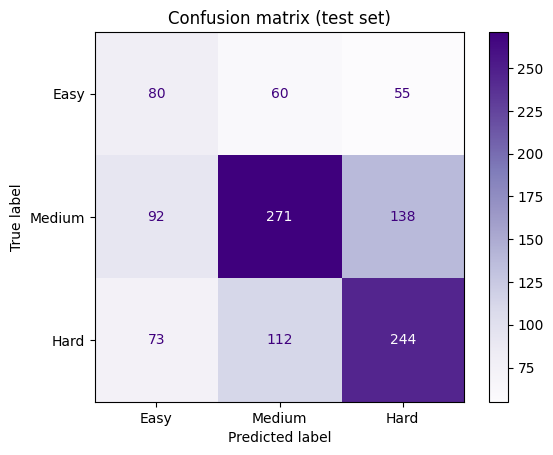

In [10]:
pred = model.predict(Xte)
acc = accuracy_score(y_test, pred)
print(f'Accuracy: {acc:.4f}\n')
print(classification_report(y_test, pred, labels=LABELS, digits=3, zero_division=0))
cm = confusion_matrix(y_test, pred, labels=LABELS)
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Purples'); plt.title('Confusion matrix (test set)'); plt.show()

### Is that good? Compare with a baseline
A **baseline** is a deliberately dumb model. If ours is not clearly better, it has learned little. **Cross-validation** repeats train/test 5 times on different splits to check that the score is stable and not just luck of one split.

In [11]:
base = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
base_pred = base.predict(X_test)
print('Baseline (always guess the commonest label) accuracy:', round(accuracy_score(y_test, base_pred), 4))
cv = cross_val_score(make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                                   LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=SEED)),
                     data['text'], data['difficulty'], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='f1_macro')
print('5-fold CV macro F1:', cv.round(3), 'mean =', round(cv.mean(), 4))

Baseline (always guess the commonest label) accuracy: 0.4453


5-fold CV macro F1: [0.506 0.502 0.522 0.514 0.53 ] mean = 0.515


**How to read this honestly:** the model beats the baseline, so it *has* learned something real from wording, but it is only **moderately** accurate. That is expected. A question's difficulty depends on the concept, the reasoning needed and the interviewer, not only on the words used, and the dataset labels may be inconsistent. So treat the prediction as a *rough hint*, never as the truth.

## Step 11 - What did the model learn?
The words with the largest positive weights for each class. This helps you sanity-check the model (and sometimes reveals dataset quirks).

In [12]:
terms = np.array(vectorizer.get_feature_names_out())
for i, cls in enumerate(model.classes_):
    print(f'{cls:7s}->', ', '.join(terms[np.argsort(-model.coef_[i])[:10]]))

Easy   -> training, pass, point, does docker, forecasting, is data, output of, json, returns, distance
Hard   -> is the, testing, problem, he, loss, control, learning, spot, kernel, rtk
Medium -> analogy, coding, number, of, deployment, sum, 1000, direction, speed, if


## Step 12 - Predict brand-new questions

In [13]:
new_questions = ['What is the difference between a list and a tuple in Python?',
                 'Design a distributed rate limiter that works across multiple data centers.',
                 'Explain how gradient descent updates the weights of a neural network.']
probs = model.predict_proba(vectorizer.transform([preprocess(q) for q in new_questions]))
for q, p in zip(new_questions, probs):
    print(f'{model.classes_[p.argmax()]:7s} ({p.max():.0%})  {q}')

Hard    (48%)  What is the difference between a list and a tuple in Python?
Hard    (61%)  Design a distributed rate limiter that works across multiple data centers.
Medium  (51%)  Explain how gradient descent updates the weights of a neural network.


## Step 13 - Save the model and vectorizer
`joblib.dump` writes the trained objects to disk. The Flask app loads these two files once at startup - it does not retrain on every web request. You must save **both**: the vectorizer to convert new text to numbers the same way, and the model to classify them.

In [14]:
out = ROOT / 'models'; out.mkdir(exist_ok=True)
joblib.dump(vectorizer, out / 'tfidf_vectorizer.joblib')
joblib.dump(model, out / 'difficulty_model.joblib')
print('Saved to', out)

Saved to /home/claude/interview-twin/models


## Step 14 - Reproducibility check and metrics file for the website
The website's **ML Model** page reads `models/metrics.json`. The script `backend/train_model.py` repeats exactly the steps above and writes that file. If it reproduces this notebook's accuracy, your results are repeatable.

In [15]:
sys.path.insert(0, str(ROOT / 'backend'))
import train_model
m = train_model.train()
print('Notebook accuracy      :', round(acc, 4))
print('Script accuracy        :', m['accuracy'])
assert round(acc, 4) == m['accuracy'], 'Notebook and script disagree - check the preprocessing steps'
print('Reproduced exactly. metrics.json written for the website.')

Notebook accuracy      : 0.5289
Script accuracy        : 0.5289
Reproduced exactly. metrics.json written for the website.


## Summary and limitations
- A **TF-IDF + Logistic Regression** classifier was trained on question wording and evaluated on unseen test data.
- The scores above are real measurements, not estimates. Compare them with the baseline before trusting the model.
- **Limitations:** difficulty cannot be fully judged from text; labels may be noisy; many questions follow templates so scores may be optimistic on genuinely new questions; the model does not understand meaning.
- **Ideas to improve it yourself:** try `LinearSVC` or `RandomForest`; add the *topic* as a feature; tune `C` with `GridSearchCV`; collect more labelled questions.